# Notebook 04 — PyTorch Fundamentals

**From tensors to training a neural network**

This notebook introduces tensors, shapes, data types, devices, autograd, datasets, data loaders, `nn.Module`, loss functions, optimizers, training, evaluation, and saving model parameters.

### Learning objectives
- Create and manipulate PyTorch tensors.
- Understand shapes, dtypes, and CPU/GPU placement.
- Use `Dataset` and `DataLoader` for mini-batch training.
- Build a model with `nn.Module`.
- Calculate gradients and update parameters.
- Train and evaluate a binary classifier.
- Save and reload model parameters.

Prerequisites: Python, NumPy, and the neural-network mathematics from the previous notebooks.

## 1. Setup

PyTorch provides tensor computation, automatic differentiation, and neural-network building blocks. Seeds make this example more reproducible, although results can still vary across hardware and software versions.

In [1]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.5.1+cu121


## 2. Tensors and shapes

A tensor is a multidimensional array. Scalars have zero dimensions, vectors one, matrices two, and higher-dimensional tensors three or more. Use `.shape` to inspect dimensions and `.ndim` to inspect the number of dimensions.

| Tensor | Example shape |
|---|---|
| Scalar | `()` |
| Vector | `(4,)` |
| Matrix | `(3, 4)` |
| 3D tensor | `(2, 3, 4)` |

In [2]:
# Create tensors with different dimensionalities.
scalar = torch.tensor(7.0)
vector = torch.tensor([1.0, 2.0, 3.0, 4.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
tensor_3d = torch.zeros((2, 3, 4))

for name, tensor in [("scalar", scalar), ("vector", vector),
                     ("matrix", matrix), ("tensor_3d", tensor_3d)]:
    print(f"{name}: shape={tuple(tensor.shape)}, ndim={tensor.ndim}")

scalar: shape=(), ndim=0
vector: shape=(4,), ndim=1
matrix: shape=(3, 2), ndim=2
tensor_3d: shape=(2, 3, 4), ndim=3


## 3. Creating tensors and data types

Common constructors include `torch.tensor`, `torch.zeros`, `torch.ones`, `torch.full`, `torch.arange`, `torch.linspace`, `torch.rand`, and `torch.randn`. Neural-network features commonly use `torch.float32`. With `BCEWithLogitsLoss`, labels are typically floating-point values shaped compatibly with the model outputs.

In [3]:
# Construct tensors using common helpers.
zeros = torch.zeros((2, 3))
ones = torch.ones((2, 3))
filled = torch.full((2, 2), 5.0)
sequence = torch.arange(0, 10, 2)
spaced = torch.linspace(0, 1, steps=5)
random_uniform = torch.rand((2, 2))
random_normal = torch.randn((2, 2))
print("zeros:\n", zeros)
print("ones:\n", ones)
print("filled:\n", filled)
print("sequence:", sequence)
print("spaced:", spaced)
print("uniform random:\n", random_uniform)
print("normal random:\n", random_normal)

features = torch.tensor([[1, 2], [3, 4]], dtype=torch.float32)
print("Feature dtype:", features.dtype)
array = np.array([1.5, 2.5, 3.5], dtype=np.float32)
print("From NumPy:", torch.from_numpy(array))

zeros:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
ones:
 tensor([[1., 1., 1.],
        [1., 1., 1.]])
filled:
 tensor([[5., 5.],
        [5., 5.]])
sequence: tensor([0, 2, 4, 6, 8])
spaced: tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])
uniform random:
 tensor([[0.8823, 0.9150],
        [0.3829, 0.9593]])
normal random:
 tensor([[ 0.2345,  0.2303],
        [-1.1229, -0.1863]])
Feature dtype: torch.float32
From NumPy: tensor([1.5000, 2.5000, 3.5000])


## 4. Reshaping and tensor operations

Shape compatibility matters throughout deep learning. Useful operations include `reshape`, `squeeze`, `unsqueeze`, `.T`, element-wise arithmetic, reductions such as `sum` and `mean`, and matrix multiplication with `@`. If `A` has shape `(m, n)` and `B` has shape `(n, p)`, then `A @ B` has shape `(m, p)`. Broadcasting allows compatible operations such as adding a bias vector to every matrix row.

In [4]:
x = torch.arange(12)
x_matrix = x.reshape(3, 4)
print("Reshaped shape:", x_matrix.shape)
print("After unsqueeze:", x_matrix.unsqueeze(0).shape)
print("After squeeze:", x_matrix.unsqueeze(0).squeeze(0).shape)

a = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
b = torch.tensor([[5.0, 6.0], [7.0, 8.0]])
bias = torch.tensor([10.0, 20.0])
print("Element-wise product:\n", a * b)
print("Matrix product:\n", a @ b)
print("Mean of columns:", a.mean(dim=0))
print("Sum of rows:", a.sum(dim=1))
print("Broadcast addition:\n", a + bias)

Reshaped shape: torch.Size([3, 4])
After unsqueeze: torch.Size([1, 3, 4])
After squeeze: torch.Size([3, 4])
Element-wise product:
 tensor([[ 5., 12.],
        [21., 32.]])
Matrix product:
 tensor([[19., 22.],
        [43., 50.]])
Mean of columns: tensor([2., 3.])
Sum of rows: tensor([3., 7.])
Broadcast addition:
 tensor([[11., 22.],
        [13., 24.]])


## 5. Device placement: CPU and GPU

Use `torch.device` to choose where computation occurs. This notebook selects a CUDA GPU when available and otherwise uses the CPU. A model and its input tensors must be on compatible devices.

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)
device_tensor = torch.ones((2, 2), device=device)
print("Tensor device:", device_tensor.device)
cpu_tensor = device_tensor.to("cpu")
print("CPU tensor device:", cpu_tensor.device)

Selected device: cuda
Tensor device: cuda:0
CPU tensor device: cpu


## 6. Automatic differentiation with autograd

Autograd computes derivatives by tracking operations on tensors with `requires_grad=True`. Calling `.backward()` calculates gradients, stored in `.grad` for tracked leaf tensors.

For $y = x^2 + 3x$,

$$
\frac{dy}{dx} = 2x + 3
$$

At $x = 2$, the derivative is $7$.

In [7]:
# Ask PyTorch to track operations involving x.
x = torch.tensor(2.0, requires_grad=True)
y = x**2 + 3 * x
y.backward()
print("y =", y.item())
print("dy/dx =", x.grad.item())  # Expected: 2 * 2 + 3 = 7

y = 10.0
dy/dx = 7.0


### 6.1 Gradients accumulate

Gradients accumulate by default when `.backward()` is called repeatedly. Training loops normally clear old gradients before each backward pass with `optimizer.zero_grad()`.

In [8]:
x = torch.tensor(3.0, requires_grad=True)
(x**2).backward()
print("First gradient:", x.grad.item())  # 2 * 3 = 6
x.grad.zero_()  # Clear the previous gradient.
(4 * x).backward()
print("Second gradient:", x.grad.item())  # 4

First gradient: 6.0
Second gradient: 4.0


## 7. Datasets and DataLoaders

A `Dataset` defines access to individual examples. A `DataLoader` batches examples and can shuffle their order. `TensorDataset` is convenient when features and labels already exist as tensors. A custom dataset usually implements `__len__()` and `__getitem__(index)`.

In [9]:
features = torch.tensor([[0.0, 0.1], [0.2, 0.3],
                         [0.8, 0.7], [0.9, 1.0]], dtype=torch.float32)
labels = torch.tensor([[0.0], [0.0], [1.0], [1.0]], dtype=torch.float32)
dataset = TensorDataset(features, labels)
loader = DataLoader(dataset, batch_size=2, shuffle=True)
for batch_features, batch_labels in loader:
    print("Batch features:\n", batch_features)
    print("Batch labels:\n", batch_labels)
    print("---")

Batch features:
 tensor([[0.0000, 0.1000],
        [0.9000, 1.0000]])
Batch labels:
 tensor([[0.],
        [1.]])
---
Batch features:
 tensor([[0.8000, 0.7000],
        [0.2000, 0.3000]])
Batch labels:
 tensor([[1.],
        [0.]])
---


In [10]:
class SimpleBinaryDataset(Dataset):
    def __init__(self, features, labels):
        self.features = features  # Store feature rows.
        self.labels = labels      # Store matching labels.

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):
        return self.features[index], self.labels[index]

custom_dataset = SimpleBinaryDataset(features, labels)
print("Number of examples:", len(custom_dataset))
print("First example:", custom_dataset[0])

Number of examples: 4
First example: (tensor([0.0000, 0.1000]), tensor([0.]))


## 8. Define a neural network with `nn.Module`

A model class inherits from `nn.Module`, registers layers in `__init__()`, and defines the forward computation in `forward()`. Registered layer parameters are tracked automatically. This classifier uses two input features, eight hidden neurons, ReLU, and one output logit. We return logits because `BCEWithLogitsLoss` combines sigmoid and binary cross-entropy in a numerically stable way.

In [11]:
class BinaryClassifier(nn.Module):
    def __init__(self, input_features=2, hidden_units=8):
        super().__init__()
        self.hidden = nn.Linear(input_features, hidden_units)
        self.output = nn.Linear(hidden_units, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.hidden(x))  # Dense layer plus non-linearity.
        return self.output(x)          # Return raw logits.

model = BinaryClassifier()
print(model)
for name, parameter in model.named_parameters():
    print(name, tuple(parameter.shape))

BinaryClassifier(
  (hidden): Linear(in_features=2, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
  (relu): ReLU()
)
hidden.weight (8, 2)
hidden.bias (8,)
output.weight (1, 8)
output.bias (1,)


## 9. Loss functions, optimizers, and one training step

The loss measures prediction error; the optimizer updates parameters using gradients. For binary labels encoded as `0.0` and `1.0`, use `nn.BCEWithLogitsLoss()` with raw logits. The standard sequence is clear gradients, forward pass, loss, `backward()`, then `optimizer.step()`.

In [12]:
model = BinaryClassifier().to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
batch_x = torch.tensor([[0.1, 0.2], [0.9, 0.8]], dtype=torch.float32).to(device)
batch_y = torch.tensor([[0.0], [1.0]], dtype=torch.float32).to(device)

model.train()
optimizer.zero_grad()
logits = model(batch_x)
loss = loss_fn(logits, batch_y)
loss.backward()
optimizer.step()
print("Batch loss:", loss.item())

Batch loss: 0.7181807160377502


## 10. Create a synthetic classification dataset

We train on a two-dimensional synthetic dataset generated by a nonlinear rule. This is a teaching example, not a biological dataset. Real projects require a scientifically appropriate split strategy and careful prevention of data leakage.

In [13]:
n_samples = 1200
X_np = np.random.normal(size=(n_samples, 2)).astype(np.float32)
noise = 0.35 * np.random.normal(size=n_samples)
scores = X_np[:, 0]**2 + 0.7 * X_np[:, 1] + noise
y_np = (scores > 0.8).astype(np.float32).reshape(-1, 1)
X_all, y_all = torch.from_numpy(X_np), torch.from_numpy(y_np)

# Shuffle indices before splitting into training and test sets.
permutation = torch.randperm(n_samples)
train_size = int(0.8 * n_samples)
train_idx, test_idx = permutation[:train_size], permutation[train_size:]
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
print("Training examples:", len(train_dataset), "Test examples:", len(X_test))

Training examples: 960 Test examples: 240


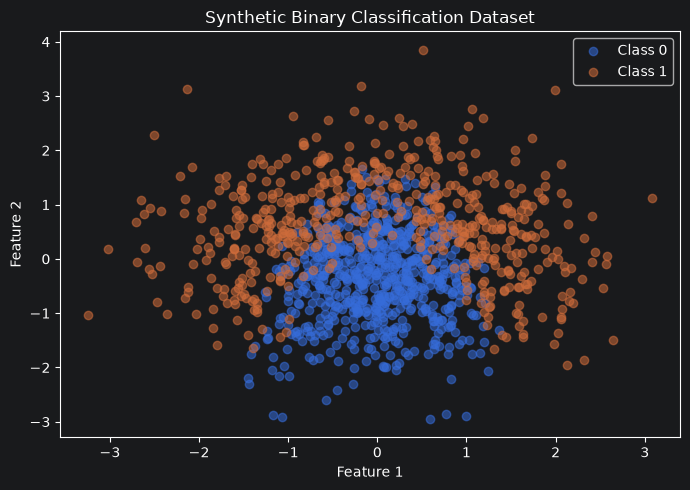

In [14]:
# Plot the two synthetic classes.
plt.figure(figsize=(7, 5))
plt.scatter(X_np[y_np[:, 0] == 0, 0], X_np[y_np[:, 0] == 0, 1], alpha=0.55, label="Class 0")
plt.scatter(X_np[y_np[:, 0] == 1, 0], X_np[y_np[:, 0] == 1, 1], alpha=0.55, label="Class 1")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Binary Classification Dataset")
plt.legend()
plt.tight_layout()
plt.show()

## 11. The complete training loop

One pass through the training data is an **epoch**. `zero_grad()` clears gradients, `backward()` calculates gradients, and `step()` updates parameters. We record sample-weighted average loss for each epoch.

In [15]:
model = BinaryClassifier().to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
epochs = 60
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss, examples_seen = 0.0, 0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        logits = model(batch_X)
        loss = loss_fn(logits, batch_y)
        loss.backward()
        optimizer.step()
        size = len(batch_X)
        total_loss += loss.item() * size
        examples_seen += size
    epoch_loss = total_loss / examples_seen
    loss_history.append(epoch_loss)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:02d}/{epochs} | loss={epoch_loss:.4f}")

Epoch 10/60 | loss=0.2567
Epoch 20/60 | loss=0.2497
Epoch 30/60 | loss=0.2460
Epoch 40/60 | loss=0.2444
Epoch 50/60 | loss=0.2465
Epoch 60/60 | loss=0.2470


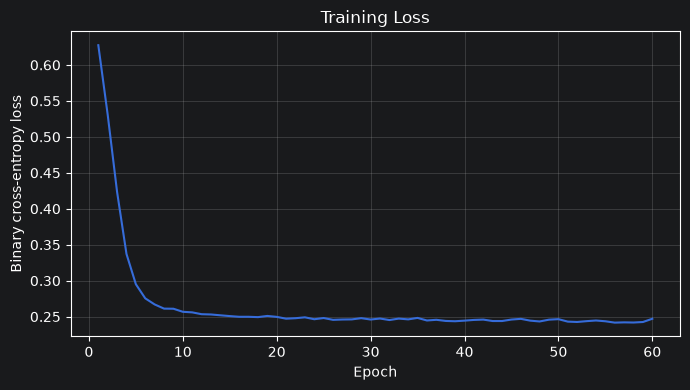

In [16]:
# Plot training loss.
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Evaluation and probabilities

Use `model.eval()` and `torch.no_grad()` for evaluation. The model outputs logits; sigmoid converts them to probabilities:

$$
p(y = 1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

For a simple accuracy score, probabilities greater than or equal to $0.5$ are classified as class 1. Accuracy alone may be insufficient for imbalanced datasets; consider precision, recall, F1 score, ROC-AUC, and calibration where appropriate.

In [17]:
model.eval()
with torch.no_grad():
    test_logits = model(X_test.to(device))
    test_probabilities = torch.sigmoid(test_logits)
    test_predictions = (test_probabilities >= 0.5).float()
accuracy = (test_predictions.cpu() == y_test).float().mean().item()
print(f"Test accuracy: {accuracy:.3f}")
print("First five probabilities:", test_probabilities[:5].cpu().squeeze().numpy())

Test accuracy: 0.900
First five probabilities: [0.00514757 0.0189744  0.04307704 0.996114   0.39304504]


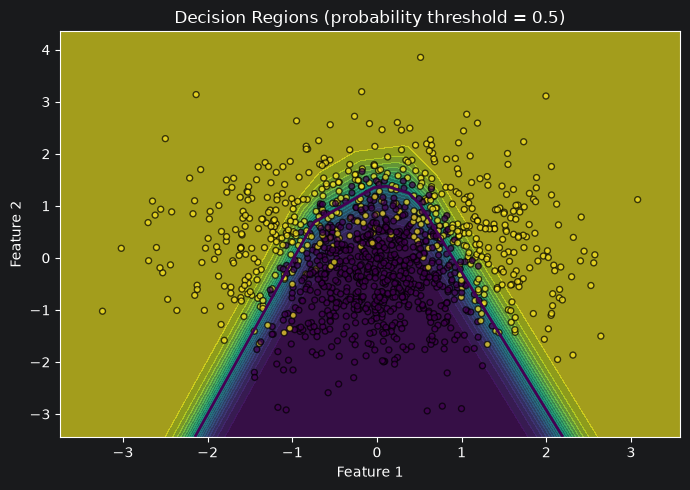

In [18]:
# Plot the learned probability surface and decision boundary.
model.eval()
x_min, x_max = X_np[:, 0].min() - 0.5, X_np[:, 0].max() + 0.5
y_min, y_max = X_np[:, 1].min() - 0.5, X_np[:, 1].max() + 0.5
grid_x, grid_y = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.column_stack([grid_x.ravel(), grid_y.ravel()]).astype(np.float32)
with torch.no_grad():
    grid_tensor = torch.from_numpy(grid).to(device)
    grid_probs = torch.sigmoid(model(grid_tensor)).cpu().numpy().reshape(grid_x.shape)
plt.figure(figsize=(7, 5))
plt.contourf(grid_x, grid_y, grid_probs, levels=20, alpha=0.65)
plt.contour(grid_x, grid_y, grid_probs, levels=[0.5], linewidths=2)
plt.scatter(X_np[:, 0], X_np[:, 1], c=y_np[:, 0], edgecolors="black", s=18, alpha=0.7)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Decision Regions (probability threshold = 0.5)")
plt.tight_layout()
plt.show()

## 13. Save and reload model parameters

A common PyTorch practice is to save a model's `state_dict`, which contains its registered parameters and buffers. Recreate the same architecture before loading those parameters.

In [19]:
model_path = "binary_classifier_state_dict.pth"
torch.save(model.state_dict(), model_path)
print("Saved to:", model_path)

loaded_model = BinaryClassifier().to(device)
state_dict = torch.load(model_path, map_location=device, weights_only=True)
loaded_model.load_state_dict(state_dict)
loaded_model.eval()
with torch.no_grad():
    probabilities = torch.sigmoid(loaded_model(X_test[:3].to(device)))
print("Loaded model probabilities:", probabilities.cpu().squeeze().numpy())

Saved to: binary_classifier_state_dict.pth
Loaded model probabilities: [0.00514757 0.0189744  0.04307704]


## 14. Common mistakes

- **Mismatched shapes:** inspect feature, label, and output shapes before calculating loss.
- **Wrong target dtype/shape:** `BCEWithLogitsLoss` expects compatible floating-point targets.
- **Different devices:** model parameters and input tensors must be on compatible devices.
- **Forgotten `zero_grad()`:** gradients accumulate by default.
- **Forgotten `backward()` or `step()`:** gradients are not calculated or parameters are not updated correctly.
- **Applying sigmoid twice:** pass raw logits to `BCEWithLogitsLoss`; apply sigmoid when probabilities are needed.
- **Incorrect evaluation mode:** call `model.eval()` for evaluation.
- **Gradient tracking during inference:** use `torch.no_grad()` or `torch.inference_mode()`.
- **Test-set leakage:** do not use test labels to update parameters or tune repeatedly.
- **Relying only on accuracy:** consider class balance and task-specific metrics.

## 15. Practice exercises

1. Create a random tensor of shape `(4, 5)` and print its shape, dtype, and device.
2. Reshape 24 elements to `(2, 3, 4)`. Explain why reshaping to `(5, 5)` fails.
3. Create a `TensorDataset` with 100 examples and a `DataLoader` with `batch_size=16`. How many batches are produced when `drop_last=False`?
4. Add a second hidden layer to `BinaryClassifier`.
5. Replace Adam with SGD and compare loss curves.
6. Add a validation split and select a model using validation loss.
7. Calculate precision, recall, and F1 score.
8. Explain why `BCEWithLogitsLoss` is often preferable to applying sigmoid and binary cross-entropy separately.
9. Save and reload a model, then verify that predictions match.
10. Replace the synthetic dataset with a real dataset and document preprocessing and data-leakage prevention.

## 16. Quick reference

| Goal | PyTorch pattern |
|---|---|
| Create tensor | `torch.tensor(data)` |
| Inspect shape | `x.shape`, `x.ndim` |
| Reshape | `x.reshape(...)` |
| Matrix multiplication | `a @ b` |
| Move to device | `x.to(device)` |
| Track gradients | `requires_grad=True` |
| Compute gradients | `loss.backward()` |
| Clear gradients | `optimizer.zero_grad()` |
| Update parameters | `optimizer.step()` |
| Define a layer | `nn.Linear(in_features, out_features)` |
| Define a model | Subclass `nn.Module`; implement `forward()` |
| Binary classification loss | `nn.BCEWithLogitsLoss()` |
| Mini-batches | `DataLoader(dataset, batch_size=..., shuffle=True)` |
| Training/evaluation | `model.train()` / `model.eval()` |
| Disable gradient tracking | `with torch.no_grad():` |
| Save parameters | `torch.save(model.state_dict(), path)` |
| Load parameters | `model.load_state_dict(state_dict)` |

**Main idea:** tensors represent data, modules represent models, autograd computes gradients, loss functions measure errors, and optimizers update parameters.